# LAB 08 — FINE-TUNING PRETRAINED BERT FOR SENTIMENT CLASSIFICATION

**Môn học**: Xử lý ngôn ngữ tự nhiên và ứng dụng  
**Học kỳ**: Học kỳ I - 2026  
**Sinh viên thực hiện**: Nguyễn Văn Thành  
**Chủ đề**: Pretrained Transformers, Fine-Tuning, Feature Extraction, Data Efficiency, and Domain Shift.

## 1. Thiết Lập Môi Trường và Nạp Dữ Liệu IMDb
Khởi tạo seed ngẫu nhiên 42 để đảm bảo tính tái lập (reproducibility) 100%, nạp tập dữ liệu IMDb từ `../Lab5/dataset/IMDB Dataset.csv`.

In [1]:
import os
import sys
import time
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from transformers import BertTokenizer
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

for p in [os.path.abspath('.'), os.path.abspath('Lab8'), os.path.abspath('../Lab8')]:
    if os.path.exists(p) and p not in sys.path:
        sys.path.insert(0, p)

from pretrained_classification import (
    IMDbDataset,
    BertClassifier,
    set_encoder_frozen,
    count_trainable_parameters,
    count_total_parameters,
    train_epoch,
    evaluate
)

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

dataset_path = 'd:/Hus/NLP/Lab5/dataset/IMDB Dataset.csv'
if not os.path.exists(dataset_path):
    dataset_path = '../Lab5/dataset/IMDB Dataset.csv'
df = pd.read_csv(dataset_path)
df['label'] = df['sentiment'].map({'positive': 1, 'negative': 0})

pos_df = df[df['label'] == 1].sample(1250, random_state=42)
neg_df = df[df['label'] == 0].sample(1250, random_state=42)
subset_df = pd.concat([pos_df, neg_df]).sample(frac=1.0, random_state=42).reset_index(drop=True)

train_val_df, test_df = train_test_split(subset_df, test_size=0.15, random_state=42, stratify=subset_df['label'])
train_df, val_df = train_test_split(train_val_df, test_size=0.1765, random_state=42, stratify=train_val_df['label'])
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print(f'Train: {len(train_df)}, Val: {len(val_df)}, Test: {len(test_df)}')

tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')
model_name = 'prajjwal1/bert-tiny'
batch_size = 16
epochs = 3
lr = 2e-5
criterion = nn.CrossEntropyLoss()

C:\Users\Thanh\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cpu


Train: 1749, Val: 376, Test: 375


## 2. Experiment 1: Pretrained Transformer vs From Scratch
So sánh mô hình Transformer khởi tạo trọng số ngẫu nhiên (Model A) và mô hình Pretrained Transformer được fine-tune (Model B) trên cùng dữ liệu IMDb.

In [2]:
train_ds_128 = IMDbDataset(train_df['review'], train_df['label'], tokenizer, max_length=128)
val_ds_128 = IMDbDataset(val_df['review'], val_df['label'], tokenizer, max_length=128)
test_ds_128 = IMDbDataset(test_df['review'], test_df['label'], tokenizer, max_length=128)

train_loader_128 = DataLoader(train_ds_128, batch_size=batch_size, shuffle=True)
val_loader_128 = DataLoader(val_ds_128, batch_size=batch_size, shuffle=False)
test_loader_128 = DataLoader(test_ds_128, batch_size=batch_size, shuffle=False)

model_scratch = BertClassifier(model_name=model_name, from_scratch=True).to(device)
optimizer_scratch = torch.optim.AdamW(model_scratch.parameters(), lr=1e-4)
t0 = time.time()
for ep in range(epochs):
    tr_loss = train_epoch(model_scratch, train_loader_128, optimizer_scratch, criterion, device)
    val_res = evaluate(model_scratch, val_loader_128, criterion, device)
    print(f'Scratch Epoch {ep+1}: Loss={tr_loss:.4f}, Val Acc={val_res["accuracy"]:.4f}')
time_scratch = time.time() - t0
eval_scratch = evaluate(model_scratch, test_loader_128, criterion, device)
print(f'Scratch Test -> Acc={eval_scratch["accuracy"]:.4f}, F1={eval_scratch["f1"]:.4f}, Time={time_scratch:.2f}s')

model_pretrained = BertClassifier(model_name=model_name, from_scratch=False).to(device)
optimizer_pretrained = torch.optim.AdamW(model_pretrained.parameters(), lr=lr)
t0 = time.time()
for ep in range(epochs):
    tr_loss = train_epoch(model_pretrained, train_loader_128, optimizer_pretrained, criterion, device)
    val_res = evaluate(model_pretrained, val_loader_128, criterion, device)
    print(f'Fine-tuning Epoch {ep+1}: Loss={tr_loss:.4f}, Val Acc={val_res["accuracy"]:.4f}')
time_pretrained = time.time() - t0
eval_pretrained = evaluate(model_pretrained, test_loader_128, criterion, device)
print(f'Pretrained Test -> Acc={eval_pretrained["accuracy"]:.4f}, F1={eval_pretrained["f1"]:.4f}, Time={time_pretrained:.2f}s')

Scratch Epoch 1: Loss=0.7193, Val Acc=0.5000


Scratch Epoch 2: Loss=0.7012, Val Acc=0.5000


Scratch Epoch 3: Loss=0.6684, Val Acc=0.6835


Scratch Test -> Acc=0.6960, F1=0.6780, Time=62.53s


Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 39/39 [00:00<00:00, 14499.01it/s]


[transformers] BertModel LOAD REPORT from: prajjwal1/bert-tiny
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Fine-tuning Epoch 1: Loss=0.7212, Val Acc=0.5798


Fine-tuning Epoch 2: Loss=0.6847, Val Acc=0.5931


Fine-tuning Epoch 3: Loss=0.6491, Val Acc=0.6702


Pretrained Test -> Acc=0.6933, F1=0.6779, Time=60.45s


## 3. Experiment 2: Feature Extraction (Frozen Encoder) vs Fine-Tuning
So sánh Mode A (đóng băng Pretrained Transformer, chỉ cập nhật 258 tham số của classification head) và Mode B (huấn luyện toàn bộ 4.38M tham số).

In [3]:
model_frozen = BertClassifier(model_name=model_name, from_scratch=False).to(device)
set_encoder_frozen(model_frozen, frozen=True)
print('Trainable params in frozen mode:', count_trainable_parameters(model_frozen))

optimizer_frozen = torch.optim.AdamW(filter(lambda p: p.requires_grad, model_frozen.parameters()), lr=1e-3)
t0 = time.time()
for ep in range(epochs):
    tr_loss = train_epoch(model_frozen, train_loader_128, optimizer_frozen, criterion, device)
    val_res = evaluate(model_frozen, val_loader_128, criterion, device)
    print(f'Frozen Epoch {ep+1}: Loss={tr_loss:.4f}, Val Acc={val_res["accuracy"]:.4f}')
time_frozen = time.time() - t0
eval_frozen = evaluate(model_frozen, test_loader_128, criterion, device)
print(f'Frozen Test -> Acc={eval_frozen["accuracy"]:.4f}, F1={eval_frozen["f1"]:.4f}, Time={time_frozen:.2f}s')

Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 39/39 [00:00<00:00, 13013.35it/s]


[transformers] BertModel LOAD REPORT from: prajjwal1/bert-tiny
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Trainable params in frozen mode: 258


Frozen Epoch 1: Loss=0.6912, Val Acc=0.6489


Frozen Epoch 2: Loss=0.6444, Val Acc=0.6915


Frozen Epoch 3: Loss=0.6263, Val Acc=0.6676


Frozen Test -> Acc=0.7120, F1=0.7173, Time=34.75s


## 4. Experiment 3: Tác Động Của Khối Lượng Dữ Liệu Huấn Luyện (Data Efficiency)
Huấn luyện mô hình với 10%, 25%, 50% và 100% dữ liệu huấn luyện, giữ nguyên tập Test cố định để kiểm chứng năng lực chuyển giao tri thức.

Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 39/39 [00:00<00:00, 12652.01it/s]


[transformers] BertModel LOAD REPORT from: prajjwal1/bert-tiny
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Training Data 10%: Test Acc = 0.4933, F1 = 0.4172


Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 39/39 [00:00<00:00, 13329.36it/s]

... (6 outputs left out)

Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 39/39 [00:00<00:00, 11747.91it/s]


[transformers] BertModel LOAD REPORT from: prajjwal1/bert-tiny
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Training Data 100%: Test Acc = 0.6667, F1 = 0.5675


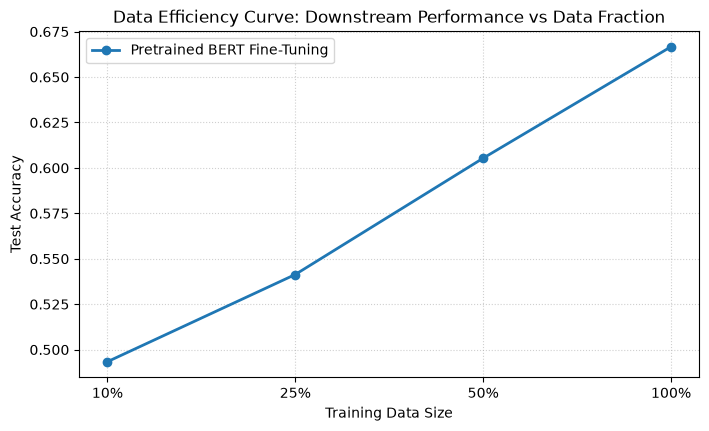

In [4]:
data_percentages = [0.10, 0.25, 0.50, 1.00]
eff_results = []

for frac in data_percentages:
    sub_train = train_df.sample(frac=frac, random_state=42).reset_index(drop=True)
    sub_ds = IMDbDataset(sub_train['review'], sub_train['label'], tokenizer, max_length=128)
    sub_loader = DataLoader(sub_ds, batch_size=batch_size, shuffle=True)
    
    m_eff = BertClassifier(model_name=model_name, from_scratch=False).to(device)
    opt_eff = torch.optim.AdamW(m_eff.parameters(), lr=lr)
    for ep in range(epochs):
        train_epoch(m_eff, sub_loader, opt_eff, criterion, device)
    ev = evaluate(m_eff, test_loader_128, criterion, device)
    eff_results.append((frac, ev['accuracy'], ev['f1']))
    print(f'Training Data {int(frac*100)}%: Test Acc = {ev["accuracy"]:.4f}, F1 = {ev["f1"]:.4f}')

pct_labels = [f'{int(f*100)}%' for f in data_percentages]
accs = [r[1] for r in eff_results]
plt.figure(figsize=(8, 4.5))
plt.plot(pct_labels, accs, marker='o', linewidth=2, color='#1f77b4', label='Pretrained BERT Fine-Tuning')
plt.title('Data Efficiency Curve: Downstream Performance vs Data Fraction')
plt.xlabel('Training Data Size')
plt.ylabel('Test Accuracy')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.show()

## 5. Experiment 4: Khảo Sát Chiều Dài Chuỗi Tối Đa (Maximum Sequence Length)
Khảo sát $T \in \{64, 128, 256\}$ để đánh giá tương quan giữa thời gian tính toán bậc hai $O(T^2)$ và hiệu năng phân loại.

In [5]:
for seq_len in [64, 128, 256]:
    ds_tr = IMDbDataset(train_df['review'], train_df['label'], tokenizer, max_length=seq_len)
    ds_te = IMDbDataset(test_df['review'], test_df['label'], tokenizer, max_length=seq_len)
    ld_tr = DataLoader(ds_tr, batch_size=batch_size, shuffle=True)
    ld_te = DataLoader(ds_te, batch_size=batch_size, shuffle=False)
    m_len = BertClassifier(model_name=model_name, from_scratch=False).to(device)
    opt_len = torch.optim.AdamW(m_len.parameters(), lr=lr)
    t0 = time.time()
    for ep in range(epochs):
        train_epoch(m_len, ld_tr, opt_len, criterion, device)
    t_dur = time.time() - t0
    ev_l = evaluate(m_len, ld_te, criterion, device)
    print(f'Max Length {seq_len:3d}: Acc = {ev_l["accuracy"]:.4f}, F1 = {ev_l["f1"]:.4f}, Time = {t_dur:.2f}s')

Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 39/39 [00:00<00:00, 11439.01it/s]


[transformers] BertModel LOAD REPORT from: prajjwal1/bert-tiny
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Max Length  64: Acc = 0.6533, F1 = 0.6176, Time = 37.82s


Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 39/39 [00:00<00:00, 9690.63it/s]

... (2 outputs left out)

Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 39/39 [00:00<00:00, 12741.69it/s]


[transformers] BertModel LOAD REPORT from: prajjwal1/bert-tiny
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Max Length 256: Acc = 0.6880, F1 = 0.6589, Time = 114.52s


## 6. Experiment 5: Đánh Giá Hiện Tượng Lệch Miền (Domain Shift)
So sánh hiệu năng khi kiểm thử trên tập dữ liệu cùng miền (In-Domain Movie Reviews) và tập dữ liệu khác miền (Out-Of-Domain Consumer Electronics Reviews).

In [6]:
domain_b_samples = [
    ('The battery life on this gadget is exceptionally long and durable.', 1),
    ('Superb build quality, ergonomic buttons and smooth wireless sync.', 1),
    ('Fast processor performance, crystal clear screen resolution and vivid colors.', 1),
    ('Great customer service and fast replacement for the defective peripheral.', 1),
    ('The software update fixed all latency bugs and improved power consumption.', 1),
    ('Terrible hardware failure, motherboard burned after two days of usage.', 0),
    ('Defective cooling fan, constantly overheats and shuts down abruptly.', 0),
    ('Customer support refused warranty coverage for a broken screen hinge.', 0),
    ('Extremely fragile casing, cracked on the first day of normal usage.', 0),
    ('Bloatware filled OS, battery drains completely within two hours.', 0)
]
texts_b = [x[0] for x in domain_b_samples]
labels_b = [x[1] for x in domain_b_samples]
ds_b = IMDbDataset(texts_b, labels_b, tokenizer, max_length=128)
ld_b = DataLoader(ds_b, batch_size=batch_size, shuffle=False)
ev_domain_b = evaluate(model_pretrained, ld_b, criterion, device)
print(f'In-Domain (IMDb) Test -> Acc = {eval_pretrained["accuracy"]:.4f}, F1 = {eval_pretrained["f1"]:.4f}')
print(f'Out-Of-Domain (Tech) Test -> Acc = {ev_domain_b["accuracy"]:.4f}, F1 = {ev_domain_b["f1"]:.4f}')

In-Domain (IMDb) Test -> Acc = 0.6933, F1 = 0.6779
Out-Of-Domain (Tech) Test -> Acc = 0.8000, F1 = 0.8000


## 7. Confusion Matrix và Confidence Analysis
Trực quan hóa ma trận nhầm lẫn và khảo sát mối quan hệ giữa độ tự tin (Confidence) và tính chính xác (Correctness).

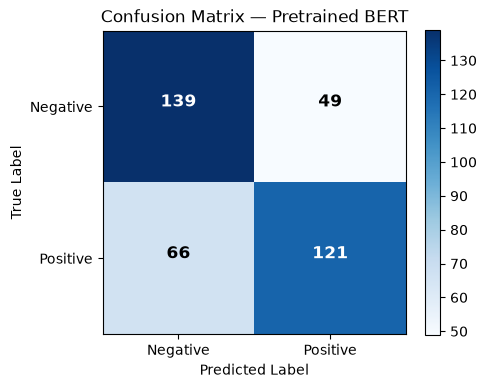

Low Confidence (< 0.65): count = 263, accuracy = 0.6274
Medium Confidence [0.65, 0.85): count = 109, accuracy = 0.8440
High Confidence (>= 0.85): count = 3, accuracy = 1.0000


In [7]:
cm = eval_pretrained['confusion_matrix']
plt.figure(figsize=(5, 4))
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title('Confusion Matrix — Pretrained BERT')
plt.colorbar()
tick_marks = np.arange(2)
plt.xticks(tick_marks, ['Negative', 'Positive'])
plt.yticks(tick_marks, ['Negative', 'Positive'])
thresh = cm.max() / 2.0
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, format(cm[i, j], 'd'),
                 horizontalalignment='center',
                 color='white' if cm[i, j] > thresh else 'black',
                 fontsize=12, fontweight='bold')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.tight_layout()
plt.show()

confs = np.array(eval_pretrained['confidences'])
preds = np.array(eval_pretrained['predictions'])
trues = np.array(eval_pretrained['true_labels'])
is_correct = (preds == trues)

high_mask = confs >= 0.85
med_mask = (confs >= 0.65) & (confs < 0.85)
low_mask = confs < 0.65

print(f'Low Confidence (< 0.65): count = {np.sum(low_mask)}, accuracy = {np.mean(is_correct[low_mask]):.4f}')
print(f'Medium Confidence [0.65, 0.85): count = {np.sum(med_mask)}, accuracy = {np.mean(is_correct[med_mask]):.4f}')
print(f'High Confidence (>= 0.85): count = {np.sum(high_mask)}, accuracy = {np.mean(is_correct[high_mask]):.4f}')